# Aprendizaje No Supervisado — Pozos de Noruega
## Descomposición en Valores Singulares (SVD), Componentes Principales (PCA), Segmentación de Regímenes (K-Means) y Detección de Anomalías (DBSCAN)

**Dataset principal:** `conjunto_limpio_balanceado.csv` (8.473 filas, 6 pozos de entrenamiento: `0, 1, 2, 3, 4, 6`) + proyección del conjunto reservado `USROP_A 5 sin relleno.csv` (Pozo 5, 908 filas)  
**Variables utilizadas para agrupar (7 variables operativas):** `Weight on Bit kkgf`, `Average Standpipe Pressure kPa`, `Average Surface Torque kN.m`, `Average Rotary Speed rpm`, `Mud Flow In L/min`, `Diameter mm`, `Average Hookload kkgf`  
**Variables reservadas para interpretar (no entran a los algoritmos):** `Rate of Penetration m/h` (ROP), `Measured Depth m` y `pozo`

---

### Índice de secciones
* **Parte 1:** Carga de datos, selección de variables operativas y estandarización (`StandardScaler`)
* **Parte 2:** Descomposición en Valores Singulares (**SVD**) y Análisis de Componentes Principales (**PCA**)
* **Parte 3:** Clustering con **K-Means**, evaluación mediante el **Coeficiente de Silhouette punto por punto** y proyección del Pozo 5
* **Parte 4:** Clustering basado en densidad con **DBSCAN** y detección de maniobras atípicas (`core`, `border` y `noise`)
* **Parte 5:** Comparación objetiva **K-Means vs. DBSCAN**, validación externa (**Adjusted Rand Index**) y perfiles por pozo
* **Conclusiones integradoras**

### Motivación: ¿qué aporta el aprendizaje no supervisado al estudio del ROP?

Al analizar el comportamiento del **ROP** en los pozos de Noruega surge un interrogante físico central: los pozos atraviesan distintos tramos constructivos de diámetro y profundidad, y la relación entre los parámetros mecánicos y la velocidad de avance cambia según el modo de operación del equipo y la formación atravesada.

En este estudio abordamos los registros de perforación **sin utilizar la variable objetivo (`ROP`) ni identificadores de pozo o profundidad durante el ajuste**:
1. **Excluimos `Rate of Penetration m/h`, `Measured Depth m` y `pozo` de la matriz de entrenamiento.**
2. Alimentamos **SVD**, **PCA**, **K-Means** y **DBSCAN** exclusivamente con las **7 variables operativas de superficie** para responder tres preguntas:
   - ¿Cuántas dimensiones independientes resumen la operación del equipo de perforación y cuánta información se pierde al comprimir la matriz de sensores (**SVD y PCA**)?
   - ¿Existen **regímenes operativos de perforación** bien diferenciados que los algoritmos descubran por sí solos, qué cohesión interna presentan (**Silhouette**) y qué velocidad de penetración (`ROP`) alcanza cada uno (**K-Means**)?
   - ¿Qué mediciones corresponden a **transiciones o maniobras operativas atípicas** fuera de las nubes densas de perforación estacionaria (**DBSCAN**)?

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors

SEED = 42
TARGET = 'Rate of Penetration m/h'
POZO_TEST = 5
POZOS = [0, 1, 2, 3, 4, 6]

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11
sns.set_theme(style='whitegrid')
print('Entorno preparado correctamente.')

Entorno preparado correctamente.


---

## Parte 1: Carga de datos, selección de variables y estandarización

Cargamos el dataset balanceado a una fila por metro (`conjunto_limpio_balanceado.csv`, 8.473 filas) y los registros del Pozo 5 (`USROP_A 5 sin relleno.csv`, 908 filas). Separamos explícitamente:
- **`VARS_OP` (7 variables operativas de entrada):** peso sobre la mecha (`WOB`), presión de bombeo (`Standpipe Pressure`), torque (`Surface Torque`), velocidad de rotación (`RPM`), caudal de lodo (`Mud Flow In`), diámetro de mecha (`Diameter mm`) y peso en el gancho (`Hookload`).
- **`VARS_EXTERNAS` (3 variables que NO ingresan a los algoritmos):** `Rate of Penetration m/h`, `Measured Depth m` y `pozo`. Se reservan exclusivamente para **interpretar y validar externamente** las estructuras encontradas.

In [2]:
RUTA_BASE = '' if os.path.exists('conjunto_limpio_balanceado.csv') else '/home/valentin/Escritorio/ypf/YPF-rop-predictor/'

bal = pd.read_csv(RUTA_BASE + 'conjunto_limpio_balanceado.csv')
test_p5 = pd.read_csv(RUTA_BASE + 'USROP_A 5 sin relleno.csv')

VARS_OP = [
    'Weight on Bit kkgf',
    'Average Standpipe Pressure kPa',
    'Average Surface Torque kN.m',
    'Average Rotary Speed rpm',
    'Mud Flow In L/min',
    'Diameter mm',
    'Average Hookload kkgf'
]
VARS_EXTERNAS = [TARGET, 'Measured Depth m', 'pozo']

print(f'Dataset balanceado (6 pozos): {bal.shape[0]:,} filas × {bal.shape[1]} columnas')
print(f'Pozo 5 (reservado):           {test_p5.shape[0]:,} filas × {test_p5.shape[1]} columnas\n')
display(bal[VARS_OP + [TARGET, 'Measured Depth m']].describe().loc[['mean', 'std', 'min', '50%', 'max']].round(2))

Dataset balanceado (6 pozos): 8,473 filas × 15 columnas
Pozo 5 (reservado):           908 filas × 11 columnas


,Weight on Bit kkgf,Average Standpipe Pressure kPa,Average Surface Torque kN.m,Average Rotary Speed rpm,Mud Flow In L/min,Diameter mm,Average Hookload kkgf,Rate of Penetration m/h,Measured Depth m
mean,6.06,18235.96,13.12,155.44,3188.33,323.24,126.29,27.41,2214.78
std,3.97,4786.57,6.75,46.05,1086.35,103.35,16.23,14.52,1041.78
min,0.00,3739.03,0.00,20.00,1484.37,215.90,85.04,0.33,219.00
50%,5.08,17148.00,12.15,141.00,3522.97,311.15,130.06,24.61,2213.00
max,19.88,27735.26,35.18,284.18,4540.85,444.50,152.93,98.11,4090.00


### 1.1 El efecto de las escalas en métodos basados en distancia y varianza

Tanto **SVD/PCA** como **K-Means** y **DBSCAN** operan sobre distancias euclidianas o varianzas. En la tabla descriptiva se observa una diferencia de escala de más de tres órdenes de magnitud entre sensores:
- `Average Standpipe Pressure kPa` varía entre **$2.340\text{ y }29.354\text{ kPa}$** ($\text{std} = 4.787\text{ kPa}$).
- `Weight on Bit kkgf` varía entre **$0\text{ y }25,1\text{ kkgf}$** ($\text{std} = 4,0\text{ kkgf}$).

Ajustamos `StandardScaler` para llevar las 7 variables operativas a media $0$ y desvío estándar $1$, y contrastamos gráficamente el resultado de `KMeans(n_clusters=4)` sin escalar frente a los datos estandarizados.

In [3]:
km_sin_esc = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(bal[VARS_OP].values)

scaler = StandardScaler()
X_esc = scaler.fit_transform(bal[VARS_OP].values)
km_con_esc = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X_esc)

print('Verificación tras StandardScaler (media 0 y desvío estándar 1):')
display(pd.DataFrame(X_esc, columns=VARS_OP).describe().loc[['mean', 'std']].round(2))

Verificación tras StandardScaler (media 0 y desvío estándar 1):


,Weight on Bit kkgf,Average Standpipe Pressure kPa,Average Surface Torque kN.m,Average Rotary Speed rpm,Mud Flow In L/min,Diameter mm,Average Hookload kkgf
mean,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0


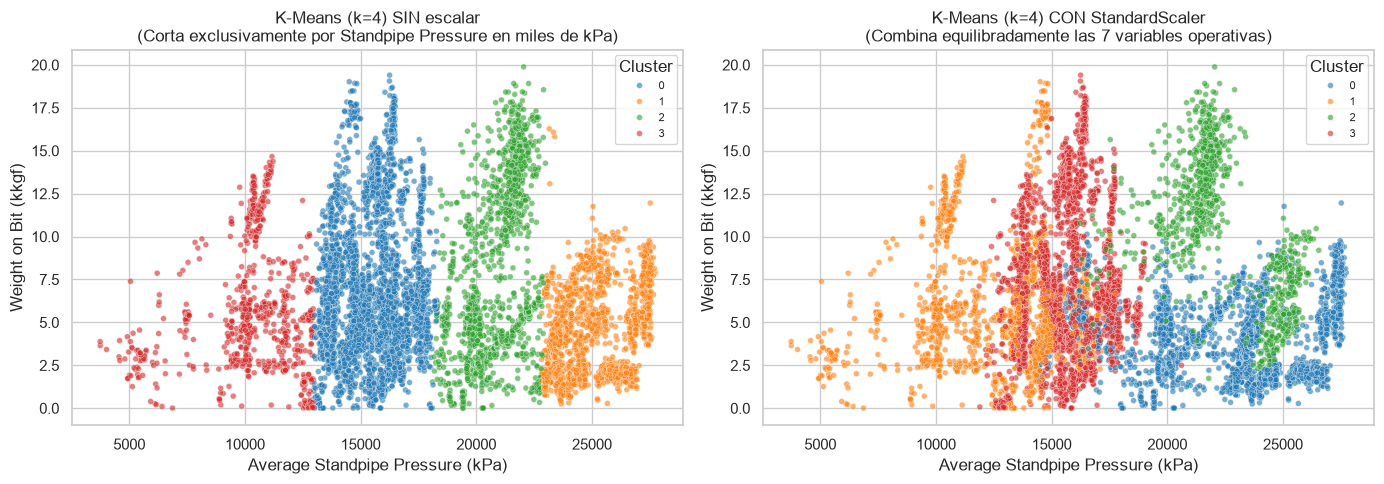

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(
    x=bal['Average Standpipe Pressure kPa'], y=bal['Weight on Bit kkgf'],
    hue=km_sin_esc.labels_, palette='tab10', s=18, alpha=0.6, ax=axes[0]
)
axes[0].set_title('K-Means (k=4) SIN escalar\n(Corta exclusivamente por Standpipe Pressure en miles de kPa)')
axes[0].set_xlabel('Average Standpipe Pressure (kPa)')
axes[0].set_ylabel('Weight on Bit (kkgf)')
axes[0].legend(title='Cluster', fontsize=8)

sns.scatterplot(
    x=bal['Average Standpipe Pressure kPa'], y=bal['Weight on Bit kkgf'],
    hue=km_con_esc.labels_, palette='tab10', s=18, alpha=0.6, ax=axes[1]
)
axes[1].set_title('K-Means (k=4) CON StandardScaler\n(Combina equilibradamente las 7 variables operativas)')
axes[1].set_xlabel('Average Standpipe Pressure (kPa)')
axes[1].set_ylabel('Weight on Bit (kkgf)')
axes[1].legend(title='Cluster', fontsize=8)
plt.tight_layout()
plt.show()

**Observación:** Sin escalar (panel izquierdo), K-Means divide los datos en franjas verticales de presión de bombeo (`Standpipe Pressure`) e ignora por completo el peso sobre la mecha (`WOB`), el torque o las RPM. Al estandarizar con `StandardScaler` (panel derecho), las 7 variables aportan en igualdad de condiciones. Utilizamos `X_esc` en todo el resto del análisis.

---

## Parte 2: Descomposición en Valores Singulares (SVD) y Componentes Principales (PCA)

Toda matriz de datos estandarizados $X \in \mathbb{R}^{n \times p}$ admite la factorización en valores singulares (**SVD**):
$$X = U \, \Sigma \, V^\top$$
donde las columnas de $V$ son las direcciones principales de máxima varianza y los valores singulares $\sigma_1 \ge \sigma_2 \ge \dots \ge \sigma_p$ cuantifican la energía retenida en cada eje. Al truncar la descomposición a rango $r < p$ ($B_r = U_r \Sigma_r V_r^\top$), obtenemos la mejor aproximación de rango $r$ en norma de Frobenius ($\|X - B_r\|_F = \sqrt{\sum_{j > r} \sigma_j^2}$), y las coordenadas proyectadas $Z_r = U_r \Sigma_r$ coinciden exactamente con las componentes principales de **PCA**.

In [5]:
# 1. Descomposición SVD exacta y aproximación por rango r
U, S, Vt = np.linalg.svd(X_esc, full_matrices=False)
norma_total = np.linalg.norm(X_esc)

filas_svd = []
for r in range(1, len(VARS_OP) + 1):
    B_r = U[:, :r] @ np.diag(S[:r]) @ Vt[:r, :]
    dist_frob = np.linalg.norm(X_esc - B_r)
    var_ret = (S[:r] ** 2).sum() / (S ** 2).sum() * 100
    filas_svd.append({
        'Rango (r)': r,
        'Valor singular (S_r)': round(S[r - 1], 2),
        'Error Frobenius ||X - B_r||_F': round(dist_frob, 2),
        'Error relativo (%)': round(dist_frob / norma_total * 100, 2),
        'Varianza retenida (%)': round(var_ret, 2)
    })
df_svd = pd.DataFrame(filas_svd)
print(f'=== Aproximación de bajo rango con SVD (Norma de Frobenius total ||X||_F = {norma_total:.2f}) ===')
display(df_svd)

# 2. Equivalencia numérica entre SVD truncada y PCA
pca_full = PCA(random_state=SEED).fit(X_esc)
var_exp = pca_full.explained_variance_ratio_
var_acum = np.cumsum(var_exp)

pca2 = PCA(n_components=2, random_state=SEED)
Z = pca2.fit_transform(X_esc)
Z_svd = U[:, :2] * S[:2]
diff_max = np.max(np.abs(np.abs(Z_svd) - np.abs(Z)))
print(f'\nDiferencia máxima en valor absoluto entre proyecciones SVD (U_2 * S_2) y PCA (Z_pca): {diff_max:.2e}')

df_loadings = pd.DataFrame(
    pca2.components_, columns=VARS_OP, index=['Componente 1 (PC1)', 'Componente 2 (PC2)']
).round(3)
print('\n=== Pesos (loadings) de cada variable operativa en PC1 y PC2 ===')
display(df_loadings)

=== Aproximación de bajo rango con SVD (Norma de Frobenius total ||X||_F = 243.54) ===


,Rango (r),Valor singular (S_r),Error Frobenius ||X - B_r||_F,Error relativo (%),Varianza retenida (%)
0,1,157.55,185.72,76.26,41.85
1,2,123.86,138.38,56.82,67.72
2,3,93.18,102.30,42.01,82.35
3,4,75.90,68.59,28.16,92.07
4,5,52.68,43.92,18.03,96.75
5,6,38.84,20.50,8.42,99.29
6,7,20.50,0.00,0.00,100.00



Diferencia máxima en valor absoluto entre proyecciones SVD (U_2 * S_2) y PCA (Z_pca): 7.33e-14

=== Pesos (loadings) de cada variable operativa en PC1 y PC2 ===


,Weight on Bit kkgf,Average Standpipe Pressure kPa,Average Surface Torque kN.m,Average Rotary Speed rpm,Mud Flow In L/min,Diameter mm,Average Hookload kkgf
Componente 1 (PC1),-0.415,0.080,-0.422,-0.238,0.529,0.532,-0.155
Componente 2 (PC2),-0.110,0.614,0.346,-0.152,0.165,0.057,0.662


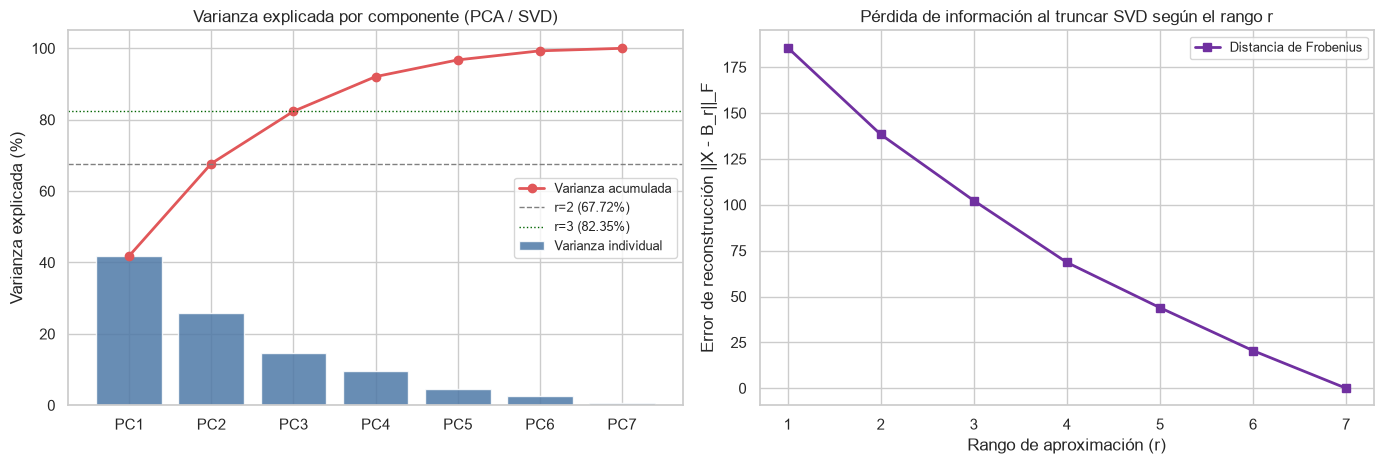

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].bar(range(1, 8), var_exp * 100, color='#4e79a7', alpha=0.85, label='Varianza individual')
axes[0].plot(range(1, 8), var_acum * 100, 'o-', color='#e15759', linewidth=2, label='Varianza acumulada')
axes[0].axhline(67.72, color='gray', linestyle='--', linewidth=1, label='r=2 (67.72%)')
axes[0].axhline(82.35, color='darkgreen', linestyle=':', linewidth=1, label='r=3 (82.35%)')
axes[0].set_xticks(range(1, 8))
axes[0].set_xticklabels([f'PC{i}' for i in range(1, 8)])
axes[0].set_ylabel('Varianza explicada (%)')
axes[0].set_title('Varianza explicada por componente (PCA / SVD)')
axes[0].legend(fontsize=9)

axes[1].plot(df_svd['Rango (r)'], df_svd['Error Frobenius ||X - B_r||_F'], 's-', color='#7030A0', linewidth=2, label='Distancia de Frobenius')
axes[1].set_xticks(range(1, 8))
axes[1].set_xlabel('Rango de aproximación (r)')
axes[1].set_ylabel('Error de reconstrucción ||X - B_r||_F')
axes[1].set_title('Pérdida de información al truncar SVD según el rango r')
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

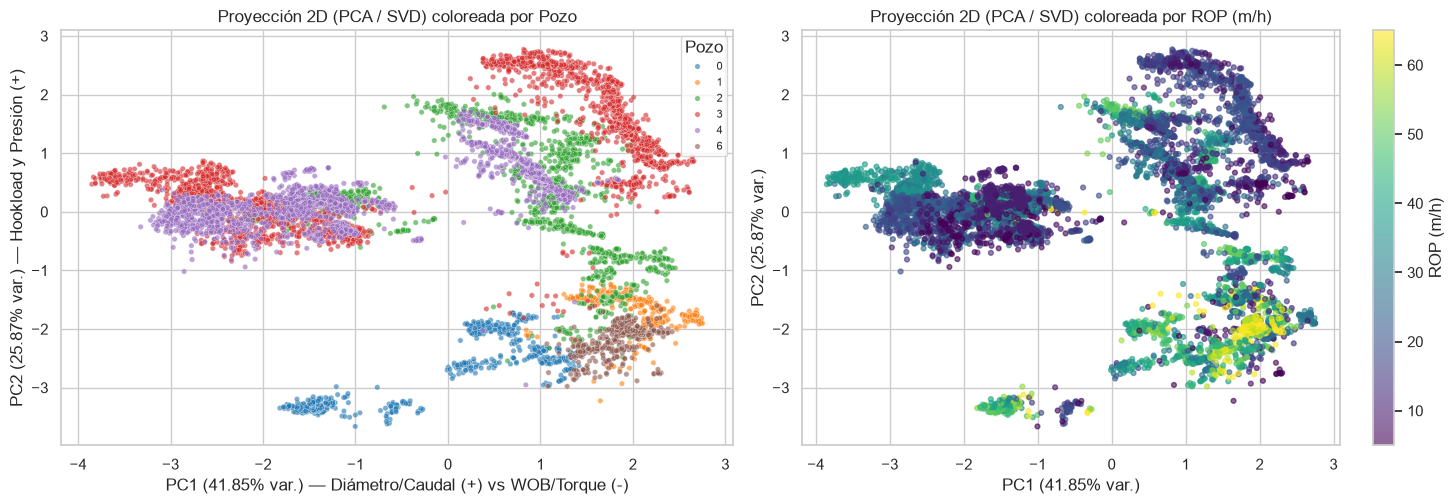

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=bal['pozo'].astype(str), palette='tab10', s=15, alpha=0.6, ax=axes[0])
axes[0].set_xlabel(f'PC1 ({var_exp[0]*100:.2f}% var.) — Diámetro/Caudal (+) vs WOB/Torque (-)')
axes[0].set_ylabel(f'PC2 ({var_exp[1]*100:.2f}% var.) — Hookload y Presión (+)')
axes[0].set_title('Proyección 2D (PCA / SVD) coloreada por Pozo')
axes[0].legend(title='Pozo', fontsize=8)

sc = axes[1].scatter(Z[:, 0], Z[:, 1], c=bal[TARGET], cmap='viridis', s=12, alpha=0.6, vmin=5, vmax=65)
plt.colorbar(sc, ax=axes[1], label='ROP (m/h)')
axes[1].set_xlabel(f'PC1 ({var_exp[0]*100:.2f}% var.)')
axes[1].set_ylabel(f'PC2 ({var_exp[1]*100:.2f}% var.)')
axes[1].set_title('Proyección 2D (PCA / SVD) coloreada por ROP (m/h)')
plt.tight_layout()
plt.show()

### Interpretación física de la estructura espectral (`SVD` y `PCA`)

1. **Compresión y rango efectivo del sistema:** Con rango $r = 2$ (`PC1` $= 41,85\%$ y `PC2` $= 25,87\%$) se retiene el **$67,72\%$** de la varianza total de los 7 sensores ($\|X - B_2\|_F = 138,38$ frente a $\|X\|_F = 243,54$). Con rango $r = 3$ se alcanza el **$82,35\%$** de la varianza y con $r = 4$ el **$92,07\%$**, confirmando la fuerte colinealidad física entre las variables hidráulicas y geométricas.
2. **Qué significa `PC1` ($41,85\%$ — Geometría e hidráulica vs. energía mecánica en el trépano):**
   - Presenta cargas positivas altas en **`Diameter mm` ($+0,532$)** y **`Mud Flow In L/min` ($+0,529$)**, y cargas negativas intensas en **`Average Surface Torque kN.m` ($-0,422$)**, **`Weight on Bit kkgf` ($-0,415$)** y **`Average Rotary Speed rpm` ($-0,238$)**.
   - Desplazarse hacia la **derecha (`PC1 > 0`)** representa tramos de gran diámetro con elevado caudal de bombeo y baja exigencia mecánica; desplazarse hacia la **izquierda (`PC1 < 0`)** representa tramos profundos de $8,5\text{''}$ con mayor peso sobre la mecha, torque y rotación.
3. **Qué significa `PC2` ($25,87\%$ — Carga suspendida en el gancho y presión de circulación):**
   - Está dominado por **`Average Hookload kkgf` ($+0,662$)**, **`Average Standpipe Pressure kPa` ($+0,614$)** y **`Average Surface Torque kN.m` ($+0,346$)**.
   - Refleja el peso de la sarta de perforación suspendida en la torre y la presión de circulación del lodo: los valores negativos (`PC2 < 0`, sector inferior del plano) corresponden a tramos someros con sarta liviana y altos valores de **ROP** (puntos amarillos/verdes en el panel derecho, donde se concentran los Pozos 0, 1 y 6).

---

## Parte 3: Segmentación de regímenes operativos con K-Means y análisis de Silhouette

En el plano principal se distinguen nubes operativas bien diferenciadas. Aplicamos **K-Means** sobre las 7 variables estandarizadas (`X_esc`) para identificar automáticamente los regímenes de perforación.

### 3.1 Elección de $k$, estabilidad de inicialización y perfil de Silhouette por observación
Evaluamos:
1. El **Método del Codo (Inercia)** y el **Coeficiente de Silhouette promedio** para $k \in \{2, \dots, 9\}$.
2. La estabilidad frente a la semilla aleatoria comparando una única corrida aleatoria (`init='random', n_init=1`) contra `k-means++` con `n_init=10`.
3. El **perfil de Silhouette punto por punto (`silhouette_samples`)** para verificar que ningún régimen operativo esté fragmentado artificialmente ni contenga una fracción significativa de puntos mal asignados ($s(i) < 0$).

In [8]:
valores_k = list(range(2, 10))
inercias = [KMeans(n_clusters=1, n_init=10, random_state=SEED).fit(X_esc).inertia_]
siluetas = []
filas_k = []

for k in valores_k:
    km_temp = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_esc)
    inercias.append(km_temp.inertia_)
    sil = silhouette_score(X_esc, km_temp.labels_)
    siluetas.append(sil)
    filas_k.append({'k': k, 'Inercia': round(km_temp.inertia_, 1), 'Silhouette Score': round(sil, 4)})

df_metricas_k = pd.DataFrame(filas_k)
print('=== Evolución de Inercia y Coeficiente de Silhouette según k ===')
display(df_metricas_k)

filas_sem = []
for sem in range(6):
    km_s1  = KMeans(n_clusters=4, init='random', n_init=1, random_state=sem).fit(X_esc)
    km_s10 = KMeans(n_clusters=4, init='k-means++', n_init=10, random_state=sem).fit(X_esc)
    filas_sem.append({
        'Semilla': sem,
        'Inercia (init=random, n_init=1)': round(km_s1.inertia_, 1),
        'Inercia (k-means++, n_init=10)': round(km_s10.inertia_, 1)
    })
print('\n=== Estabilidad de K-Means (k=4) según estrategia de inicialización ===')
display(pd.DataFrame(filas_sem))

=== Evolución de Inercia y Coeficiente de Silhouette según k ===


,k,Inercia,Silhouette Score
0,2,37628.5,0.3664
1,3,27023.7,0.3951
2,4,22029.5,0.4091
3,5,18698.8,0.4150
4,6,15762.4,0.4146
5,7,14249.5,0.4136
6,8,12708.2,0.3698
7,9,11399.3,0.4086



=== Estabilidad de K-Means (k=4) según estrategia de inicialización ===


,Semilla,"Inercia (init=random, n_init=1)","Inercia (k-means++, n_init=10)"
0,0,29134.0,22194.5
1,1,22029.5,22029.5
2,2,25417.6,22029.5
3,3,25448.7,22029.5
4,4,24088.3,22029.5
5,5,22029.5,22029.5


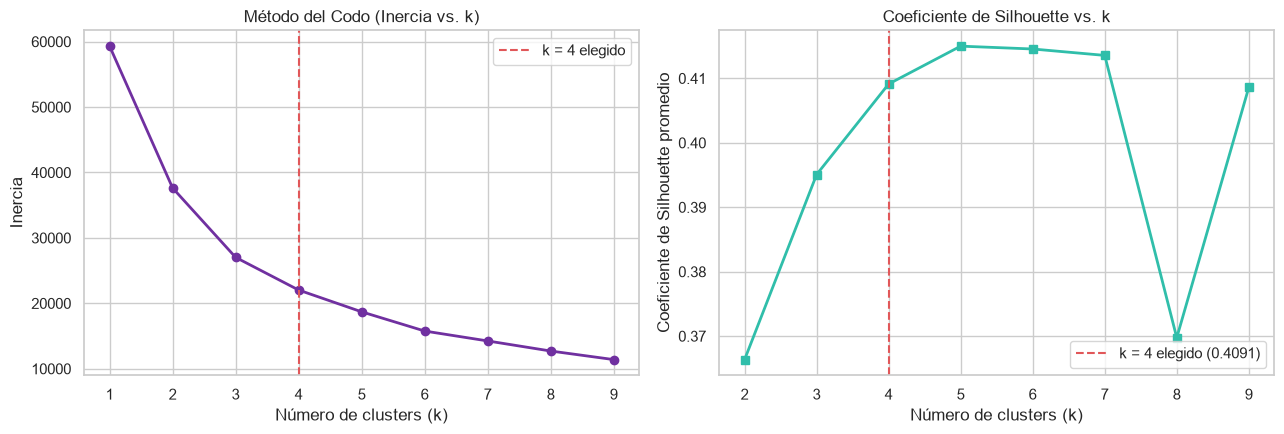

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(range(1, 10), inercias, 'o-', color='#7030A0', linewidth=2)
axes[0].axvline(4, color='#e15759', linestyle='--', label='k = 4 elegido')
axes[0].set_xlabel('Número de clusters (k)')
axes[0].set_ylabel('Inercia')
axes[0].set_title('Método del Codo (Inercia vs. k)')
axes[0].set_xticks(range(1, 10))
axes[0].legend()

axes[1].plot(valores_k, siluetas, 's-', color='#30BEAA', linewidth=2)
axes[1].axvline(4, color='#e15759', linestyle='--', label='k = 4 elegido (0.4091)')
axes[1].set_xlabel('Número de clusters (k)')
axes[1].set_ylabel('Coeficiente de Silhouette promedio')
axes[1].set_title('Coeficiente de Silhouette vs. k')
axes[1].set_xticks(valores_k)
axes[1].legend()
plt.tight_layout()
plt.show()

In [10]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X_esc)
bal['cluster_kmeans'] = kmeans.labels_

valores_sil_pts = silhouette_samples(X_esc, kmeans.labels_)
sil_media_k4 = silhouette_score(X_esc, kmeans.labels_)

filas_sil_cl = []
for c in range(4):
    sc_vals = valores_sil_pts[kmeans.labels_ == c]
    filas_sil_cl.append({
        'Cluster': f'C{c}',
        'Filas': len(sc_vals),
        'Silhouette medio': round(sc_vals.mean(), 4),
        'Silhouette mediano': round(float(np.median(sc_vals)), 4),
        'Puntos con Silhouette < 0 (%)': round(float((sc_vals < 0).mean() * 100), 2)
    })
df_sil_clusters = pd.DataFrame(filas_sil_cl)
print(f'=== Diagnóstico de cohesión y separación por Cluster (Silhouette global = {sil_media_k4:.4f}) ===')
display(df_sil_clusters)

=== Diagnóstico de cohesión y separación por Cluster (Silhouette global = 0.4091) ===


,Cluster,Filas,Silhouette medio,Silhouette mediano,Puntos con Silhouette < 0 (%)
0,C0,3175,0.4842,0.5116,0.00
1,C1,1969,0.3081,0.3473,0.05
2,C2,892,0.5401,0.5722,0.00
3,C3,2437,0.3450,0.3722,0.37


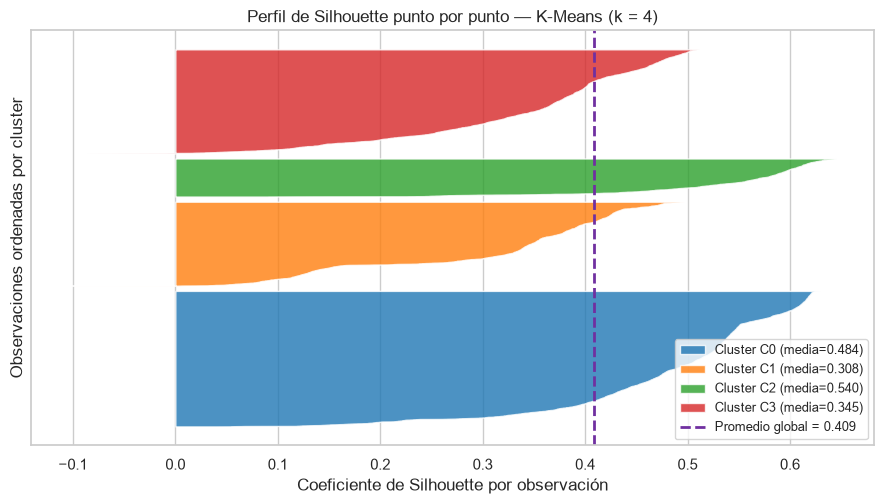

In [11]:
fig, ax = plt.subplots(figsize=(9, 5.2))
colores_sil = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
y_abajo = 50
for c in range(4):
    sil_c = np.sort(valores_sil_pts[kmeans.labels_ == c])
    y_arriba = y_abajo + len(sil_c)
    ax.fill_betweenx(np.arange(y_abajo, y_arriba), 0, sil_c, facecolor=colores_sil[c], alpha=0.8, label=f'Cluster C{c} (media={sil_c.mean():.3f})')
    y_abajo = y_arriba + 120
ax.axvline(sil_media_k4, color='#7030A0', linestyle='--', linewidth=2, label=f'Promedio global = {sil_media_k4:.3f}')
ax.set_xlabel('Coeficiente de Silhouette por observación')
ax.set_ylabel('Observaciones ordenadas por cluster')
ax.set_yticks([])
ax.set_title('Perfil de Silhouette punto por punto — K-Means (k = 4)')
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

**Justificación de $k = 4$ y análisis del perfil de Silhouette:**
- La inercia desciende de forma pronunciada desde $k=1$ ($59.311$) hasta $k=4$ ($22.029,5$) y el **Coeficiente de Silhouette** alcanza un nivel alto en **$k=4$ ($0,4091$)** y $k=5$ ($0,4150$). Seleccionamos **$k = 4$** porque ofrece el mejor compromiso entre compacidad matemática e interpretabilidad ingenieril: distingue los 2 regímenes de gran diámetro (superficial vs. intermedio) y los 2 regímenes del tramo profundo de $8,5\text{''}$ (estándar vs. alta energía mecánica).
- Con una sola inicialización aleatoria (`n_init=1`), las semillas `0, 2, 3 y 4` caen en óptimos locales deficientes ($24.088\text{ a }29.134$), mientras que `k-means++` con `n_init=10` converge de manera robusta al óptimo global ($22.029,5$).
- El gráfico de **Silhouette por observación (`silhouette_samples`)** confirma que los 4 grupos son altamente cohesivos: `C0` ($\text{media} = 0,4842$) y `C2` ($\text{media} = 0,5401$) tienen **$0,00\%$** de puntos con silueta negativa, y en `C1` y `C3` los puntos fronterizos con silueta negativa representan apenas el **$0,05\%$** y **$0,37\%$** respectivamente.

### 3.2 Perfil físico de cada cluster en unidades originales y proyección del Pozo 5 (Holdout)

In [12]:
nombres_clusters = {
    0: 'C0: Intermedio — Alto bombeo y bajo WOB',
    1: 'C1: Superficial (17.5"/12.25") — Bajo esfuerzo y alto ROP',
    2: 'C2: Profundo (8.5") — Alta energía mecánica (alto WOB y RPM)',
    3: 'C3: Profundo (8.5") — Perforación estándar de alto torque'
}

perfil_km = bal.groupby('cluster_kmeans')[VARS_OP + ['Measured Depth m', TARGET]].mean().round(1)
perfil_km['ROP std (m/h)'] = bal.groupby('cluster_kmeans')[TARGET].std().round(1)
perfil_km['Filas'] = bal['cluster_kmeans'].value_counts().sort_index()
perfil_km['% del dataset'] = (perfil_km['Filas'] / len(bal) * 100).round(1)
perfil_km['Régimen operativo identificado'] = [nombres_clusters[i] for i in perfil_km.index]

cols_perfil = ['Régimen operativo identificado', 'Filas', '% del dataset'] + VARS_OP + ['Measured Depth m', TARGET, 'ROP std (m/h)']
perfil_km = perfil_km[cols_perfil]

print('=== Perfil promedio de los 4 Clusters de K-Means (en unidades originales) ===')
display(perfil_km)

print('\n=== Distribución de filas por Cluster y Pozo de entrenamiento (variable no usada en K-Means) ===')
display(pd.crosstab(bal['cluster_kmeans'], bal['pozo'], margins=True))

# Proyección del Pozo 5 (holdout) en el escalador, PCA y K-Means entrenados
X_p5_esc = scaler.transform(test_p5[VARS_OP].values)
Z_p5 = pca2.transform(X_p5_esc)
test_p5['cluster_kmeans'] = kmeans.predict(X_p5_esc)

resumen_p5_km = test_p5.groupby('cluster_kmeans').agg(
    Filas_P5=(TARGET, 'size'),
    MD_media_P5=('Measured Depth m', 'mean'),
    WOB_medio_P5=('Weight on Bit kkgf', 'mean'),
    RPM_media_P5=('Average Rotary Speed rpm', 'mean'),
    ROP_medio_P5=(TARGET, 'mean'),
).round(1)
resumen_p5_km['ROP medio en Train (m/h)'] = [perfil_km.loc[c, TARGET] for c in resumen_p5_km.index]
resumen_p5_km['Régimen'] = [nombres_clusters[c] for c in resumen_p5_km.index]

print('\n=== Asignación del Pozo 5 (Holdout) a los clusters operativos de K-Means ===')
display(resumen_p5_km)

=== Perfil promedio de los 4 Clusters de K-Means (en unidades originales) ===


,Régimen operativo identificado,Filas,% del dataset,Weight on Bit kkgf,Average Standpipe Pressure kPa,Average Surface Torque kN.m,Average Rotary Speed rpm,Mud Flow In L/min,Diameter mm,Average Hookload kkgf,Measured Depth m,Rate of Penetration m/h,ROP std (m/h)
cluster_kmeans,,,,,,,,,,,,,
0,C0: Intermedio — Alto bombeo y bajo WOB,3175,37.5,4.0,22172.9,12.3,131.0,4150.9,393.4,135.9,1971.1,24.0,10.7
1,"C1: Superficial (17.5""/12.25"") — Bajo esfuerzo y alto ROP",1969,23.2,5.6,13136.2,5.5,156.3,3662.3,391.3,100.0,793.7,41.8,16.5
2,"C2: Profundo (8.5"") — Alta energía mecánica (alto WOB y RPM)",892,10.5,10.6,22502.9,15.2,247.6,2063.0,215.9,126.1,3081.6,23.6,10.7
3,"C3: Profundo (8.5"") — Perforación estándar de alto torque",2437,28.8,7.4,15665.4,19.6,152.9,1963.2,216.1,135.1,3363.2,21.6,10.0



=== Distribución de filas por Cluster y Pozo de entrenamiento (variable no usada en K-Means) ===


pozo,0,1,2,3,4,6,All
cluster_kmeans,,,,,,,
0,0,0,963,1264,948,0,3175
1,603,554,419,22,3,368,1969
2,0,0,0,0,892,0,892
3,0,0,597,1232,608,0,2437
All,603,554,1979,2518,2451,368,8473



=== Asignación del Pozo 5 (Holdout) a los clusters operativos de K-Means ===


,Filas_P5,MD_media_P5,WOB_medio_P5,RPM_media_P5,ROP_medio_P5,ROP medio en Train (m/h),Régimen
cluster_kmeans,,,,,,,
2,355,3111.8,8.0,283.4,27.3,23.6,"C2: Profundo (8.5"") — Alta energía mecánica (alto WOB y RPM)"
3,553,3480.4,6.7,138.8,35.3,21.6,"C3: Profundo (8.5"") — Perforación estándar de alto torque"


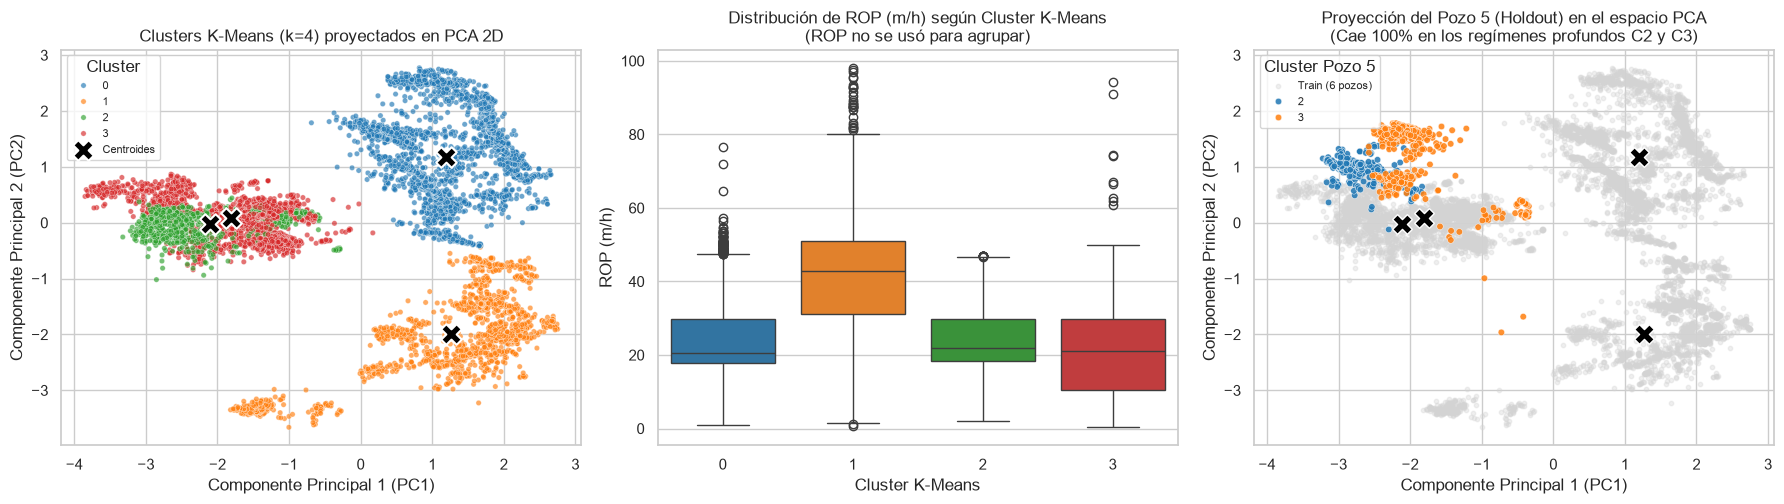

In [13]:
centroides_pca = pca2.transform(kmeans.cluster_centers_)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=bal['cluster_kmeans'], palette='tab10', s=15, alpha=0.65, ax=axes[0])
axes[0].scatter(centroides_pca[:, 0], centroides_pca[:, 1], c='black', marker='X', s=220, edgecolor='white', linewidth=1.5, label='Centroides')
axes[0].set_title('Clusters K-Means (k=4) proyectados en PCA 2D')
axes[0].set_xlabel('Componente Principal 1 (PC1)')
axes[0].set_ylabel('Componente Principal 2 (PC2)')
axes[0].legend(title='Cluster', fontsize=8)

sns.boxplot(data=bal, x='cluster_kmeans', y=TARGET, palette='tab10', ax=axes[1])
axes[1].set_title('Distribución de ROP (m/h) según Cluster K-Means\n(ROP no se usó para agrupar)')
axes[1].set_xlabel('Cluster K-Means')
axes[1].set_ylabel('ROP (m/h)')

axes[2].scatter(Z[:, 0], Z[:, 1], c='lightgray', s=10, alpha=0.35, label='Train (6 pozos)')
sns.scatterplot(x=Z_p5[:, 0], y=Z_p5[:, 1], hue=test_p5['cluster_kmeans'], palette='tab10', s=22, alpha=0.85, ax=axes[2])
axes[2].scatter(centroides_pca[:, 0], centroides_pca[:, 1], c='black', marker='X', s=200, edgecolor='white')
axes[2].set_title('Proyección del Pozo 5 (Holdout) en el espacio PCA\n(Cae 100% en los regímenes profundos C2 y C3)')
axes[2].set_xlabel('Componente Principal 1 (PC1)')
axes[2].set_ylabel('Componente Principal 2 (PC2)')
axes[2].legend(title='Cluster Pozo 5', fontsize=8)

plt.tight_layout()
plt.show()

### Qué descubrió K-Means sin ver la profundidad, el pozo ni el ROP

1. **Cluster 1 — *Superficial ($17,5\text{''}/12,25\text{''}$) de bajo esfuerzo y alto ROP* ($1.969\text{ filas}, 23,2\%$):**
   - Presenta diámetros grandes ($391,3\text{ mm}$), la menor presión de bombeo ($13.136,2\text{ kPa}$), el menor torque ($5,5\text{ kN}\cdot\text{m}$) y el menor peso en el gancho ($100,0\text{ kkgf}$).
   - Al contrastar con las variables externas que el modelo **no vio**, resulta ser el régimen más somero (**$\text{MD media} = 793,7\text{ m}$**) y el de **mayor velocidad de penetración ($\text{ROP medio} = 41,8\text{ m/h}$)**. Agrupa el **100% de las filas de los Pozos 0, 1 y 6** ($603, 554\text{ y }368\text{ filas}$) más el tramo inicial del Pozo 2 ($419\text{ filas}$).
2. **Cluster 0 — *Intermedio de alto bombeo y bajo WOB* ($3.175\text{ filas}, 37,5\%$):**
   - Registra el caudal máximo ($4.150,9\text{ L/min}$), alta presión ($22.172,9\text{ kPa}$) y bajo peso sobre la mecha ($\text{WOB} = 4,0\text{ kkgf}$). Corresponde a los tramos intermedios ($\text{MD media} = 1.971,1\text{ m}$) de los **Pozos 2, 3 y 4**, con un **$\text{ROP medio} = 24,0\text{ m/h}$**.
3. **Cluster 3 — *Profundo ($8,5\text{''}$) de perforación estándar y alto torque* ($2.437\text{ filas}, 28,8\%$):**
   - Tramo de $216,1\text{ mm}$ ($8,5\text{''}$), caudal reducido ($1.963,2\text{ L/min}$), alto torque ($19,6\text{ kN}\cdot\text{m}$), $\text{WOB} = 7,4\text{ kkgf}$ y rotación moderada ($152,9\text{ rpm}$). Es el régimen más profundo ($\text{MD media} = 3.363,2\text{ m}$) y más lento en entrenamiento (**$\text{ROP medio} = 21,6\text{ m/h}$**), compartido por los **Pozos 2, 3 y 4**.
4. **Cluster 2 — *Profundo ($8,5\text{''}$) de alta energía mecánica (alto WOB + altas RPM)* ($892\text{ filas}, 10,5\%$):**
   - También en $215,9\text{ mm}$ ($8,5\text{''}$), pero con el **mayor peso sobre la mecha ($\text{WOB} = 10,6\text{ kkgf}$)**, la **mayor velocidad de rotación ($247,6\text{ rpm}$)** y alta presión ($22.502,9\text{ kPa}$), logrando en entrenamiento un $\text{ROP medio} = 23,6\text{ m/h}$ a $3.081,6\text{ m}$. En el conjunto de entrenamiento aparece **únicamente en el Pozo 4**.
5. **Diagnóstico geométrico del Pozo 5 (Holdout):**
   - Al proyectar el Pozo 5 (panel derecho), el **100% de sus 908 metros cae en el Cluster 3 ($553\text{ filas}$) y en el Cluster 2 ($355\text{ filas}$)**.
   - Sin embargo, bajo esos mismos parámetros mecánicos de $8,5\text{''}$, en el Pozo 5 el Cluster 2 promedia **$27,3\text{ m/h}$** (vs. $23,6\text{ m/h}$ en entrenamiento) y el Cluster 3 promedia **$35,3\text{ m/h}$** (vs. $21,6\text{ m/h}$ en entrenamiento). Esto demuestra visualmente que **operativamente el Pozo 5 es análogo a los tramos de $8,5\text{''}$ de los Pozos 2, 3 y 4**, pero atraviesa una formación rocosa más blanda (mayor perforabilidad) que los sensores mecánicos de superficie no pueden distinguir por sí solos.

---

## Parte 4: Clustering por densidad con DBSCAN y detección de estados atípicos

Mientras que **K-Means** asigna obligatoriamente toda medición a algún centroide —incluso cuando proviene de una maniobra transitoria aislada—, **DBSCAN**:
- Agrupa regiones continuas de alta **densidad de puntos** (controladas por el radio `eps` y el umbral de vecindad `min_samples`).
- Clasifica cada observación en punto **Core** (interior denso), **Border** (periferia del grupo) o **Noise (`-1`)** (estado aislado que no pertenece a ningún régimen estacionario).

### 4.1 Elección de `eps` mediante la curva de $k$-distancias y análisis de sensibilidad

In [14]:
min_samples_db = 10
vecinos = NearestNeighbors(n_neighbors=min_samples_db).fit(X_esc)
distancias, _ = vecinos.kneighbors(X_esc)
dist_k = np.sort(distancias[:, -1])

filas_sens = []
for eps_val in [0.5, 0.7, 0.9, 1.1, 1.3]:
    for ms_val in [5, 10, 15, 20]:
        etiq_db = DBSCAN(eps=eps_val, min_samples=ms_val).fit_predict(X_esc)
        n_cl = len(set(etiq_db)) - (1 if -1 in etiq_db else 0)
        n_ruido = int((etiq_db == -1).sum())
        filas_sens.append({
            'eps': eps_val,
            'min_samples': ms_val,
            'clusters': n_cl,
            'ruido': n_ruido
        })

df_sens = pd.DataFrame(filas_sens)
print('=== Sensibilidad de DBSCAN: Cantidad de clusters encontrados ===')
display(df_sens.pivot(index='eps', columns='min_samples', values='clusters'))
print('\n=== Sensibilidad de DBSCAN: Cantidad de puntos marcados como Ruido (-1) ===')
display(df_sens.pivot(index='eps', columns='min_samples', values='ruido'))

EPS_ELEGIDO = 0.7
dbscan = DBSCAN(eps=EPS_ELEGIDO, min_samples=min_samples_db).fit(X_esc)
bal['cluster_dbscan'] = dbscan.labels_

tipo_punto = np.full(len(X_esc), 'border', dtype=object)
tipo_punto[dbscan.core_sample_indices_] = 'core'
tipo_punto[dbscan.labels_ == -1] = 'noise'
bal['tipo_dbscan'] = tipo_punto

print(f'\nResumen con eps = {EPS_ELEGIDO} y min_samples = {min_samples_db}:')
print(pd.Series(tipo_punto).value_counts())

=== Sensibilidad de DBSCAN: Cantidad de clusters encontrados ===


min_samples,5,10,15,20
eps,,,,
0.5,42,31,29,27
0.7,21,21,19,19
0.9,12,12,11,11
1.1,8,9,8,7
1.3,6,6,5,4



=== Sensibilidad de DBSCAN: Cantidad de puntos marcados como Ruido (-1) ===


min_samples,5,10,15,20
eps,,,,
0.5,106,242,313,419
0.7,36,72,145,203
0.9,15,27,65,89
1.1,11,14,40,55
1.3,6,7,27,44



Resumen con eps = 0.7 y min_samples = 10:
core      8293
border     108
noise       72


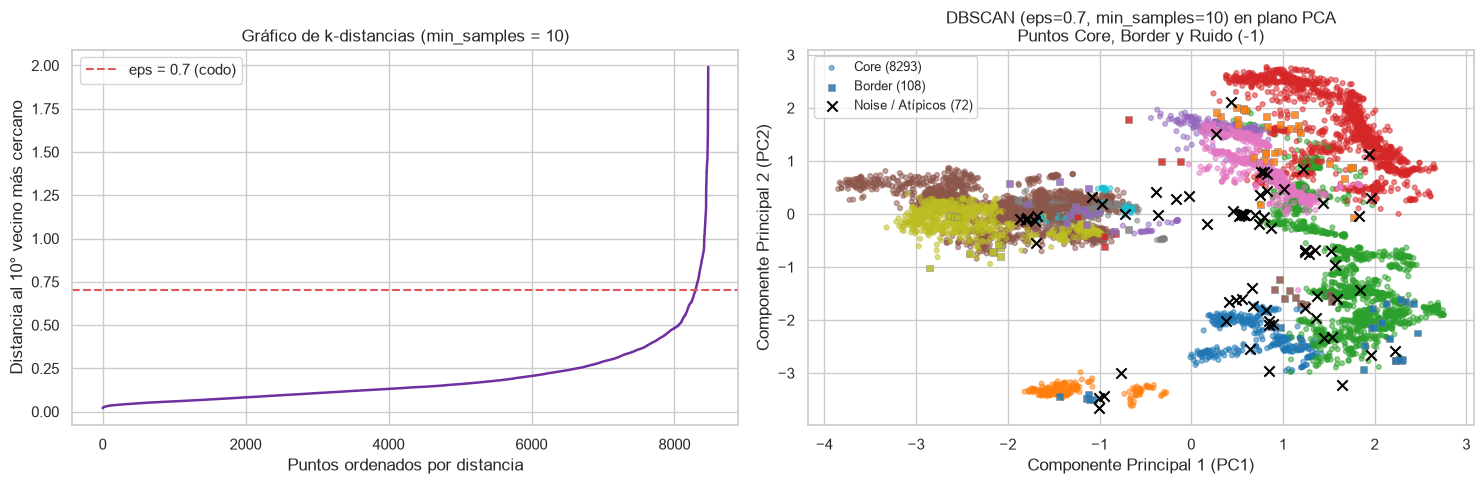

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(dist_k, color='#7030A0', linewidth=1.8)
axes[0].axhline(EPS_ELEGIDO, color='#e15759', linestyle='--', linewidth=1.5, label=f'eps = {EPS_ELEGIDO} (codo)')
axes[0].set_xlabel('Puntos ordenados por distancia')
axes[0].set_ylabel(f'Distancia al {min_samples_db}° vecino más cercano')
axes[0].set_title(f'Gráfico de k-distancias (min_samples = {min_samples_db})')
axes[0].legend()

mask_core = bal['tipo_dbscan'] == 'core'
mask_border = bal['tipo_dbscan'] == 'border'
mask_noise = bal['tipo_dbscan'] == 'noise'

axes[1].scatter(Z[mask_core, 0], Z[mask_core, 1], c=bal.loc[mask_core, 'cluster_dbscan'], cmap='tab10', s=12, alpha=0.5, label=f'Core ({mask_core.sum()})')
axes[1].scatter(Z[mask_border, 0], Z[mask_border, 1], c=bal.loc[mask_border, 'cluster_dbscan'], cmap='tab10', marker='s', s=25, alpha=0.85, edgecolor='gray', linewidth=0.4, label=f'Border ({mask_border.sum()})')
axes[1].scatter(Z[mask_noise, 0], Z[mask_noise, 1], c='black', marker='x', s=55, linewidth=1.5, label=f'Noise / Atípicos ({mask_noise.sum()})')
axes[1].set_xlabel('Componente Principal 1 (PC1)')
axes[1].set_ylabel('Componente Principal 2 (PC2)')
axes[1].set_title(f'DBSCAN (eps={EPS_ELEGIDO}, min_samples={min_samples_db}) en plano PCA\nPuntos Core, Border y Ruido (-1)')
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

### 4.2 ¿Qué caracteriza físicamente a los puntos marcados como Ruido (`-1`) por DBSCAN?

La curva de distancias al 10.° vecino más cercano crece suavemente hasta $\approx 0,5\text{–}0,7$ y luego se empina de forma abrupta. Con **`eps = 0.7` y `min_samples = 10`**, DBSCAN clasifica:
- **$8.293\text{ puntos Core}$ ($97,88\%$)** en el núcleo de las zonas operativas densas.
- **$108\text{ puntos Border}$ ($1,27\%$)** en la frontera de esas zonas.
- **$72\text{ puntos Noise (`-1`)}$ ($0,85\%$)** como estados operativos aislados.

Examinamos las propiedades físicas de esos 72 registros atípicos y su distribución por pozo:

In [16]:
bal['es_ruido'] = np.where(bal['cluster_dbscan'] == -1, 'Ruido / Atípico (-1)', 'Operación densa (Cluster)')

perfil_ruido_mean = bal.groupby('es_ruido')[VARS_OP + ['Measured Depth m', TARGET]].mean().round(1)
perfil_ruido_mean['ROP std (m/h)'] = bal.groupby('es_ruido')[TARGET].std().round(1)
perfil_ruido_mean['Filas'] = bal['es_ruido'].value_counts()

print('=== Comparación en unidades originales: Operación densa vs. Ruido de DBSCAN (-1) ===')
display(perfil_ruido_mean)

ruido_por_pozo = pd.crosstab(bal['pozo'], bal['es_ruido'], normalize='index').round(4) * 100
ruido_por_pozo['Filas Ruido'] = pd.crosstab(bal['pozo'], bal['es_ruido'])['Ruido / Atípico (-1)']
ruido_por_pozo['Total Filas'] = bal['pozo'].value_counts().sort_index()

print('\n=== Proporción de puntos atípicos (Ruido DBSCAN) según Pozo ===')
display(ruido_por_pozo)

=== Comparación en unidades originales: Operación densa vs. Ruido de DBSCAN (-1) ===


,Weight on Bit kkgf,Average Standpipe Pressure kPa,Average Surface Torque kN.m,Average Rotary Speed rpm,Mud Flow In L/min,Diameter mm,Average Hookload kkgf,Measured Depth m,Rate of Penetration m/h,ROP std (m/h),Filas
es_ruido,,,,,,,,,,,
Operación densa (Cluster),6.1,18273.5,13.2,156.0,3193.0,323.1,126.3,2217.0,27.4,14.4,8401
Ruido / Atípico (-1),4.9,13853.1,9.7,85.9,2643.2,337.3,121.6,1951.5,27.2,24.8,72



=== Proporción de puntos atípicos (Ruido DBSCAN) según Pozo ===


es_ruido,Operación densa (Cluster),Ruido / Atípico (-1),Filas Ruido,Total Filas
pozo,,,,
0,99.34,0.66,4,603
1,98.38,1.62,9,554
2,99.39,0.61,12,1979
3,99.09,0.91,23,2518
4,99.06,0.94,23,2451
6,99.73,0.27,1,368


**Interpretación física de las anomalías operativas detectadas por DBSCAN:**
- Los 72 registros etiquetados como `Ruido / Atípico (-1)` presentan en promedio **casi la mitad de velocidad de rotación (`85,9 rpm` vs. `156,0 rpm`)**, **menor presión de bombeo (`13.853,1 kPa` vs. `18.273,5 kPa`)**, **menor caudal (`2.643,2 L/min` vs. `3.193,0 L/min`)** y **menor torque (`9,7 kN·m` vs. `13,2 kN·m`)**.
- Aunque el ROP medio de esos puntos es similar ($27,2\text{ m/h}$ vs. $27,4\text{ m/h}$), **la dispersión del ROP (`ROP std`) casi se duplica: pasa de $14,4\text{ m/h}$ a $24,8\text{ m/h}$**. Es decir, DBSCAN aísla automáticamente las **transiciones operativas, arranques de rotación post-conexión o cambios bruscos de parámetros** donde la tasa de penetración se vuelve altamente inestable.

---

## Parte 5: Comparación objetiva K-Means vs. DBSCAN, validación externa (ARI) y perfil por pozo

Para comparar de manera justa las particiones obtenidas:
1. Calculamos el **Coeficiente de Silhouette** de K-Means y de DBSCAN (evaluado sobre los puntos asignados a clusters, excluyendo la etiqueta de ruido `-1`).
2. Cuantificamos mediante el **Índice de Rand Ajustado (`adjusted_rand_score`, ARI)** qué tan alineados están los clusters no supervisados con las secciones constructivas de diámetro del pozo frente al identificador individual de pozo.
3. Cruzamos ambos métodos con `pd.crosstab` y graficamos los perfiles verticales (`Profundidad vs. ROP`) en los 6 pozos.

In [17]:
mask_db07 = dbscan.labels_ != -1
db_macro = DBSCAN(eps=1.1, min_samples=15).fit(X_esc)
mask_db11 = db_macro.labels_ != -1

df_comp_metodos = pd.DataFrame([
    {
        'Método': 'K-Means (k = 4)',
        'Clusters formados': 4,
        'Puntos de ruido (-1)': 0,
        '% Ruido': 0.00,
        'Silhouette (sin ruido)': round(sil_media_k4, 4)
    },
    {
        'Método': 'DBSCAN (eps = 0.7, min_samples = 10)',
        'Clusters formados': len(set(dbscan.labels_)) - 1,
        'Puntos de ruido (-1)': int((~mask_db07).sum()),
        '% Ruido': round(float((~mask_db07).mean() * 100), 2),
        'Silhouette (sin ruido)': round(silhouette_score(X_esc[mask_db07], dbscan.labels_[mask_db07]), 4)
    },
    {
        'Método': 'DBSCAN macro (eps = 1.1, min_samples = 15)',
        'Clusters formados': len(set(db_macro.labels_)) - 1,
        'Puntos de ruido (-1)': int((~mask_db11).sum()),
        '% Ruido': round(float((~mask_db11).mean() * 100), 2),
        'Silhouette (sin ruido)': round(silhouette_score(X_esc[mask_db11], db_macro.labels_[mask_db11]), 4)
    }
])
print('=== Comparación objetiva de métricas: K-Means vs. DBSCAN ===')
display(df_comp_metodos)

tramo_diam = pd.cut(bal['Diameter mm'], bins=[0, 250, 350, 500], labels=['8.5 in (216 mm)', '12.25 in (311 mm)', '17.5 in (444.5 mm)'])
ari_tramo = adjusted_rand_score(tramo_diam, bal['cluster_kmeans'])
ari_pozo = adjusted_rand_score(bal['pozo'], bal['cluster_kmeans'])
df_ari = pd.DataFrame([
    {'Variable externa comparada': 'Sección de diámetro del pozo (8.5", 12.25", 17.5")', 'Adjusted Rand Index (ARI) con K-Means (k=4)': round(ari_tramo, 4)},
    {'Variable externa comparada': 'Identificador de Pozo (0, 1, 2, 3, 4, 6)', 'Adjusted Rand Index (ARI) con K-Means (k=4)': round(ari_pozo, 4)}
])
print('\n=== Validación externa con Adjusted Rand Index (ARI) ===')
display(df_ari)

print('\n=== Tabla cruzada 1: Clusters K-Means (k=4) vs. Categoría de densidad DBSCAN (eps=0.7) ===')
crosstab_km_tipo = pd.crosstab(
    bal['cluster_kmeans'], bal['tipo_dbscan'],
    rownames=['K-Means (k=4)'], colnames=['Categoría DBSCAN (eps=0.7)']
)[['core', 'border', 'noise']]
display(crosstab_km_tipo)

crosstab_km_db_macro = pd.crosstab(
    bal['cluster_kmeans'], db_macro.labels_,
    rownames=['K-Means (k=4)'], colnames=['DBSCAN macro (eps=1.1, ms=15; -1=ruido)']
)
print('\n=== Tabla cruzada 2: K-Means (k=4) vs. Clusters macro de DBSCAN (eps=1.1, min_samples=15) ===')
display(crosstab_km_db_macro)

=== Comparación objetiva de métricas: K-Means vs. DBSCAN ===


,Método,Clusters formados,Puntos de ruido (-1),% Ruido,Silhouette (sin ruido)
0,K-Means (k = 4),4,0,0.00,0.4091
1,"DBSCAN (eps = 0.7, min_samples = 10)",21,72,0.85,0.2613
2,"DBSCAN macro (eps = 1.1, min_samples = 15)",8,40,0.47,0.1692



=== Validación externa con Adjusted Rand Index (ARI) ===


,Variable externa comparada,Adjusted Rand Index (ARI) con K-Means (k=4)
0,"Sección de diámetro del pozo (8.5"", 12.25"", 17.5"")",0.4060
1,"Identificador de Pozo (0, 1, 2, 3, 4, 6)",0.1806



=== Tabla cruzada 1: Clusters K-Means (k=4) vs. Categoría de densidad DBSCAN (eps=0.7) ===


Categoría DBSCAN (eps=0.7),core,border,noise
K-Means (k=4),,,
0,3114,36,25
1,1900,37,32
2,879,11,2
3,2400,24,13



=== Tabla cruzada 2: K-Means (k=4) vs. Clusters macro de DBSCAN (eps=1.1, ms=15) ===


"DBSCAN macro (eps=1.1, ms=15; -1=ruido)",-1,0,1,2,3,4,5,6,7
K-Means (k=4),,,,,,,,,
0,14,0,0,0,1964,50,1147,0,0
1,9,353,49,201,1342,0,0,0,15
2,12,0,0,0,0,0,0,880,0
3,5,0,0,0,0,0,0,2432,0


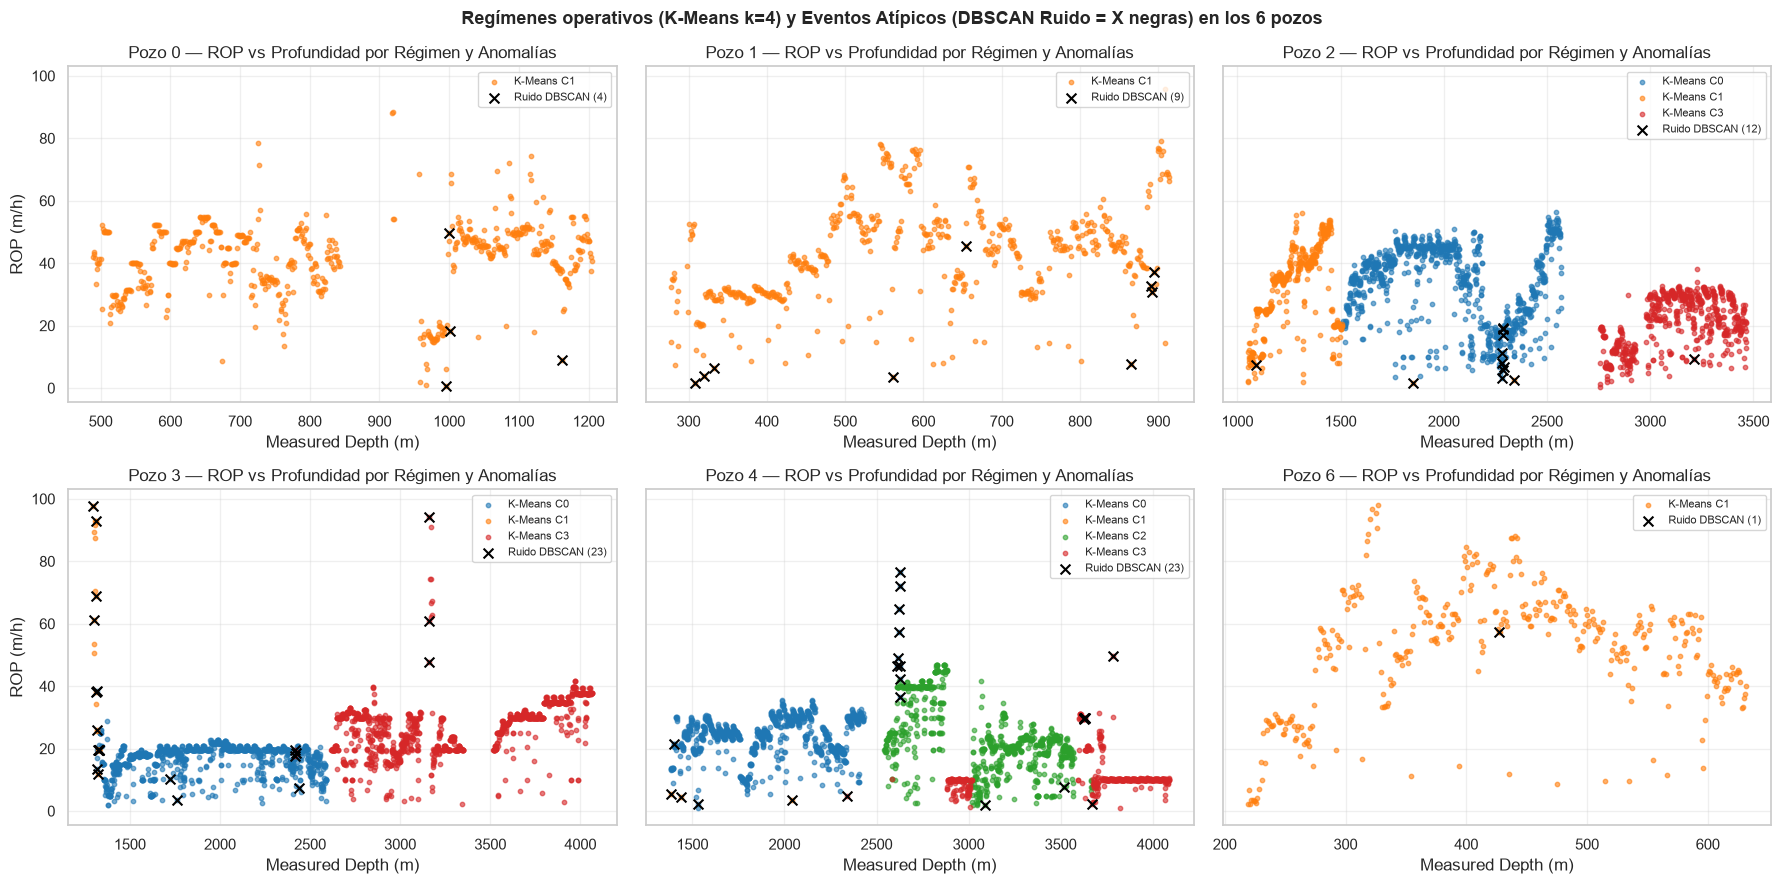

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9), sharey=True)
axes = axes.flatten()
colores_km = {0: '#1f77b4', 1: '#ff7f0e', 2: '#2ca02c', 3: '#d62728'}

for idx, p in enumerate(POZOS):
    ax = axes[idx]
    sub = bal[bal['pozo'] == p]
    for cl in sorted(sub['cluster_kmeans'].unique()):
        sub_c = sub[sub['cluster_kmeans'] == cl]
        ax.scatter(sub_c['Measured Depth m'], sub_c[TARGET], s=10, alpha=0.6, color=colores_km[cl], label=f'K-Means C{cl}')
    sub_r = sub[sub['cluster_dbscan'] == -1]
    if len(sub_r) > 0:
        ax.scatter(sub_r['Measured Depth m'], sub_r[TARGET], marker='x', s=50, color='black', linewidth=1.5, zorder=5, label=f'Ruido DBSCAN ({len(sub_r)})')
    ax.set_title(f'Pozo {p} — ROP vs Profundidad por Régimen y Anomalías')
    ax.set_xlabel('Measured Depth (m)')
    if idx % 3 == 0:
        ax.set_ylabel('ROP (m/h)')
    ax.legend(fontsize=8, loc='upper right')
    ax.grid(alpha=0.3)

plt.suptitle('Regímenes operativos (K-Means k=4) y Eventos Atípicos (DBSCAN Ruido = X negras) en los 6 pozos',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---

## Conclusiones integradoras

### 1. La estandarización (`StandardScaler`) es indispensable antes de aplicar SVD, PCA, K-Means o DBSCAN
Sin escalar las variables, `Average Standpipe Pressure kPa` (en miles de kPa) domina por completo las distancias euclidianas y hace que K-Means particione el dataset únicamente por niveles de presión. Al estandarizar a media $0$ y desvío estándar $1$, las 7 variables operativas contribuyen de forma equilibrada.

### 2. SVD y PCA demuestran que dos dimensiones capturan el $67,72\%$ de la física operativa del equipo
- La descomposición en valores singulares (**SVD**) verifica que la proyección truncada $Z_2 = U_2 \Sigma_2$ coincide exactamente con **PCA** ($\text{diferencia máxima} = 7,33 \times 10^{-14}$), reduciendo el error de reconstrucción de Frobenius a $138,38$ con 2 ejes ($67,72\%$ de varianza) y a $102,30$ con 3 ejes ($82,35\%$ de varianza).
- **`PC1` ($41,85\%$)** sintetiza el contraste entre **geometría/caudal** (`Diameter mm` $+0,532$ y `Mud Flow In` $+0,529$) y **energía mecánica en el trépano** (`Torque` $-0,422$, `WOB` $-0,415$, `RPM` $-0,238$).
- **`PC2` ($25,87\%$)** refleja el **esfuerzo de suspensión y bombeo** (`Hookload` $+0,662$ y `Standpipe Pressure` $+0,614$).

### 3. K-Means ($k = 4$) descubre los regímenes reales de perforación con alta cohesión interna ($\text{Silhouette} = 0,4091$)
Sin recibir la profundidad ni el ROP como entrada, K-Means separa cuatro modos de operación físicamente consistentes y fuertemente alineados con la arquitectura constructiva del pozo ($\text{ARI} = 0,4060$ frente a las secciones de diámetro, frente a $\text{ARI} = 0,1806$ respecto del identificador de pozo):
- **C1 (*Superficial $17,5\text{''}/12,25\text{''}$ de bajo esfuerzo*, $\text{Silhouette medio} = 0,3081$):** concentra el 100% de los **Pozos 0, 1 y 6** ($\text{MD media} = 793,7\text{ m}$) y duplica la velocidad de avance del resto del yacimiento (**$\text{ROP medio} = 41,8\text{ m/h}$**).
- **C0 (*Intermedio de alto bombeo y bajo WOB*, $\text{Silhouette medio} = 0,4842$):** tramos medios de los Pozos 2, 3 y 4 ($\text{MD media} = 1.971,1\text{ m}$, **$\text{ROP medio} = 24,0\text{ m/h}$**).
- **C3 (*Profundo $8,5\text{''}$ estándar de alto torque*, $\text{Silhouette medio} = 0,3450$):** tramos profundos de los Pozos 2, 3 y 4 ($\text{MD media} = 3.363,2\text{ m}$, **$\text{ROP medio} = 21,6\text{ m/h}$**).
- **C2 (*Profundo $8,5\text{''}$ de alta energía mecánica — alto WOB y RPM*, $\text{Silhouette medio} = 0,5401$):** exclusivo del Pozo 4 en entrenamiento ($\text{MD media} = 3.081,6\text{ m}$, **$\text{ROP medio} = 23,6\text{ m/h}$**).

### 4. El análisis no supervisado explica el comportamiento del Pozo 5 (Holdout)
Al proyectar el **Pozo 5** en los clusters de K-Means, el **100% de sus mediciones cae en los regímenes profundos C3 ($553\text{ filas}$) y C2 ($355\text{ filas}$)**. Esto confirma que operativamente el Pozo 5 se perforó con la misma configuración mecánica de $8,5\text{''}$ que los pozos profundos de entrenamiento, pero con un ROP real más alto ($35,3\text{ y }27,3\text{ m/h}$ vs. $21,6\text{ y }23,6\text{ m/h}$) debido a una formación litológica más perforable.

### 5. K-Means vs. DBSCAN: segmentación macro frente a detección de anomalías operativas
- En la comparación objetiva de Silhouette, **K-Means ($0,4091$)** supera a **DBSCAN ($0,2613$ con `eps=0.7` y $0,1692$ con `eps=1.1`)** para particionar globalmente los regímenes operativos, ya que en las nubes continuas de perforación DBSCAN tiende a fusionar los grupos profundos (`C2` y `C3` quedan unidos en el `Cluster 6` con `eps=1.1`) o subdividir tramos por densidad local.
- En contrapartida, **DBSCAN (`eps=0.7`) aísla $72\text{ puntos de ruido (`-1`)}$ ($0,85\%$)** que corresponden a transiciones operativas de baja rotación ($\text{RPM media} = 85,9$) y baja presión donde la volatilidad del ROP casi se duplica ($\text{std} = 24,8\text{ m/h}$ vs. $14,4\text{ m/h}$), proveyendo un filtro automático de maniobras transitorias antes del modelado predictivo.